# FD001: từ một dự đoán RUL đến đánh giá mô hình

**Học viên:** Phan Nguyễn Mai Phương — **MSHV:** 25002711

Một dự đoán đúng ở engine 1 chưa đủ để chọn mô hình. Notebook này chạy lại ba mô hình trên 5 fold
tách theo động cơ, chọn bằng MAE, rồi mới đánh giá trên test và xét thời điểm cảnh báo.

Dữ liệu đầu vào là 126 rolling features và nhãn đã chuẩn bị trong repo, cùng schema ở notebook 00.
Theo dõi lại **train engine 1 tại cycle 100, RUL thật = 92** để đọc một sai số cụ thể trước khi tổng hợp.

Các mô hình, dự đoán và bảng đánh giá mới được ghi vào `outputs/notebook03/run-*/`.
Phần huấn luyện chạy lại thật; các số trong phần giải thích là mốc đối chiếu của baseline đã bàn giao.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src/cmapss").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Chia theo động cơ trước khi huấn luyện

Các cửa sổ gần nhau của cùng động cơ dùng nhiều phép đo trùng nhau. GroupKFold giữ riêng toàn bộ
lịch sử của một động cơ trong mỗi lượt đánh giá, để mô hình không học các cửa sổ lân cận của nó.
Mỗi fold có 20 động cơ validation và 80 động cơ train.

In [2]:
from cmapss.modeling.baseline import prepare_modeling_dataset, build_group_folds, ModelingConfig

FEATURE_PATH = ROOT / "outputs/features/gold/rolling_features.parquet"
TARGET_PATH = ROOT / "outputs/etl/silver/train_targets.parquet"
features = pd.read_parquet(FEATURE_PATH)
targets = pd.read_parquet(TARGET_PATH)
dataset = prepare_modeling_dataset(features, targets)
config = ModelingConfig()
folds = build_group_folds(dataset, n_splits=config.n_splits)
assert folds.engine_id.nunique() == 100 and not folds.engine_id.duplicated().any()
folds.groupby("fold").agg(validation_engines=("engine_id", "nunique"))

,validation_engines
fold,
1,20
2,20
3,20
4,20
5,20


Engine 1 thuộc một fold cố định. Các dự đoán OOF (out-of-fold, dự đoán trên phần giữ riêng)
cho động cơ này phải đến từ mô hình không được huấn luyện bằng bất kỳ cửa sổ nào của engine 1.

In [3]:
example_fold = int(folds.loc[folds.engine_id.eq(1), "fold"].item())
train_ids = set(folds.loc[folds.fold.ne(example_fold), "engine_id"])
validation_ids = set(folds.loc[folds.fold.eq(example_fold), "engine_id"])
assert train_ids.isdisjoint(validation_ids) and 1 not in train_ids
pd.Series({"fold_of_engine_1": example_fold, "train_engines": len(train_ids),
           "validation_engines": len(validation_ids), "train_windows": dataset.engine_id.isin(train_ids).sum()})

fold_of_engine_1          3
train_engines            80
validation_engines       20
train_windows         14185
dtype: int64

Ba phương án dùng cùng 126 features:

- `median_baseline`: dự đoán trung vị RUL có trọng số từ phần train của fold.
- `ridge_alpha_1`: StandardScaler rồi hồi quy Ridge, alpha = 1; scaler chỉ fit trên phần train.
- `hist_gradient_boosting`: 200 vòng tăng cường cây, learning rate 0,05, tối đa 31 lá mỗi cây,
  ít nhất 20 mẫu mỗi lá; không dùng early stopping.

Trọng số huấn luyện là $1/n_i$ cho mỗi cửa sổ của động cơ $i$, nên tổng trọng số mỗi động cơ bằng nhau.
Tiêu chí đánh giá `mean_engine_mae` cũng cho mỗi động cơ trọng số như nhau.

In [4]:
import tempfile
from cmapss.modeling.baseline import run_modeling_pipeline, write_modeling_artifacts
from threadpoolctl import threadpool_limits

output_root = ROOT / "outputs/notebook03"
output_root.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(tempfile.mkdtemp(prefix="run-", dir=output_root))
with threadpool_limits(limits=2):
    fitted = run_modeling_pipeline(FEATURE_PATH, TARGET_PATH, config=config)
model_info = write_modeling_artifacts(fitted, OUTPUT)
oof = fitted.oof_predictions
selected = fitted.selected_model

## 2. Đọc một sai số, rồi tính MAE theo động cơ

Ở cycle 100, nhãn của engine 1 là 92. Sai số tuyệt đối của một mô hình là
$|\hat y - 92|$. Bảng dưới lấy ba dự đoán OOF vừa tạo tại đúng khóa đó.

In [5]:
from cmapss.modeling.metrics import add_prediction_errors

oof = add_prediction_errors(oof)
example = oof.query("engine_id == 1 and cycle == 100")
assert example.y_true.eq(92).all() and example.fold.eq(example_fold).all()
example[["model_name", "fold", "y_true", "y_pred", "absolute_error"]].round(3)

,model_name,fold,y_true,y_pred,absolute_error
7163,median_baseline,3,92.0,83.000,9.000
24894,ridge_alpha_1,3,92.0,101.663,9.663
42625,hist_gradient_boosting,3,92.0,100.700,8.700


Trong baseline đã bàn giao, HGB dự đoán khoảng 100,70 ở mẫu này, sai số khoảng 8,70 cycle.
Để chọn mô hình, cần tính trên tất cả cửa sổ của từng động cơ, rồi lấy trung bình 20 động cơ trong fold.
Gộp mọi cửa sổ ngay từ đầu sẽ khiến động cơ sống lâu có trọng số lớn hơn.

In [6]:
engine_mae = oof.groupby(["fold", "model_name", "engine_id"]).absolute_error.mean()
fold_mae = engine_mae.groupby(["fold", "model_name"]).mean().unstack("model_name")
cv = fold_mae
recorded_cv = fitted.fold_metrics.pivot(index="fold", columns="model_name", values="mean_engine_mae")
np.testing.assert_allclose(cv, recorded_cv.reindex(index=cv.index, columns=cv.columns))
assert cv.mean().idxmin() == selected
pd.concat([cv, cv.agg(["mean", "std"])]).round(2)

model_name,hist_gradient_boosting,median_baseline,ridge_alpha_1
1,20.98,47.14,24.79
2,19.05,46.96,23.68
3,20.64,46.96,24.18
4,19.27,46.88,22.51
5,21.14,46.83,24.79
mean,20.21,46.95,23.99
std,0.98,0.12,0.95


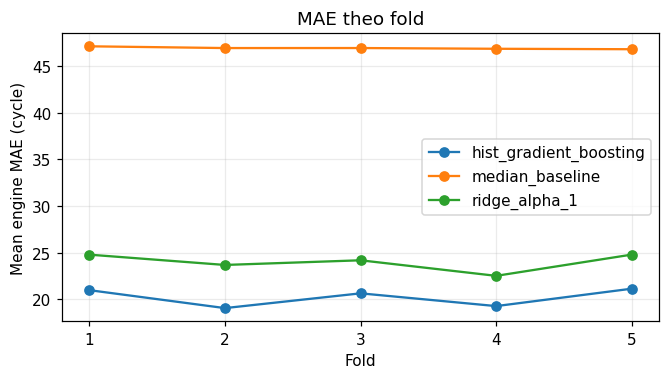

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for name in cv.columns:
    ax.plot(cv.index, cv[name], marker="o", label=name)
ax.set(xlabel="Fold", ylabel="Mean engine MAE (cycle)", title="MAE theo fold", xticks=range(1, 6))
ax.legend()
plt.show()

HistGradientBoosting có MAE trung bình 20.21 cycle, thấp hơn Ridge (23.99) khoảng 3.8 cycle
và thấp hơn một nửa baseline trung vị (46.95). MAE của HistGradientBoosting thấp hơn Ridge ở cả năm fold,
với chênh lệch 3.2–4.6 cycle; độ lệch chuẩn giữa các fold khoảng 1 cycle.
Kết quả chọn HistGradientBoosting vì vậy nhất quán trên 5 fold đã xét. Phần này chưa thực hiện kiểm định thống kê.

## 3. Chọn xong mô hình mới đọc nhãn test

Pipeline đã fit lại mô hình được chọn trên toàn bộ train và ghi 100 dự đoán tại endpoint test.
Bây giờ mới đọc nhãn test để chấm điểm. Một động cơ có một endpoint nên MAE theo cửa sổ và theo động cơ
trùng nhau trong bước này.

Khoảng tin cậy 95% được **tính lại** bằng bootstrap theo 100 động cơ, 10.000 lần, seed 42.

In [8]:
from cmapss.modeling.baseline import evaluate_predictions_from_path, write_final_evaluation_artifacts
from cmapss.modeling.metrics import summarize_prediction_errors

LABEL_PATH = ROOT / "data/raw/RUL_FD001.txt"
evaluation = evaluate_predictions_from_path(OUTPUT / "predictions/final_predictions.parquet", LABEL_PATH)
final_metrics = write_final_evaluation_artifacts(
    evaluation, OUTPUT, test_label_path=LABEL_PATH,
    bootstrap_resamples=config.bootstrap_resamples, seed=config.seed,
)
metrics = summarize_prediction_errors(evaluation)
intervals = pd.DataFrame(final_metrics["bootstrap"]["intervals"]).T
intervals.insert(0, "point", [metrics[name] for name in intervals.index])
intervals

,point,ci_lower,ci_upper
mean_engine_mae,15.349047,12.728607,18.086554
rmse,20.541267,17.344213,23.585015
nasa_score,1513.257656,743.499920,2476.274259


MAE test là 15.35 cycle, khoảng tin cậy 12.73–18.09; RMSE là 20.54.
NASA score bằng 1513 với khoảng tin cậy 743–2476. Khoảng này rộng vì hàm phạt mũ khiến một vài
trường hợp dự đoán RUL quá cao có thể làm tổng điểm tăng mạnh.

MAE test thấp hơn MAE cross-validation (20.21), nhưng hai kết quả dùng các điểm đánh giá khác nhau.
CV tính trên toàn bộ quỹ đạo từ cycle 30, gồm cả giai đoạn đầu đời có RUL lớn.
Test chỉ đánh giá tại cycle cuối, với RUL thật từ 7–145 cycle.

## 4. Sai số lớn ở đoạn nào của vòng đời?

Residual = dự đoán − giá trị thật. Residual dương là dự đoán còn nhiều thời gian hơn thực tế,
có thể làm chậm quyết định bảo trì. NASA score phạt phía dương nặng hơn:
$e^{d/10}-1$ khi $d \ge 0$, còn phía âm dùng $e^{-d/13}-1$.

Tách test theo RUL thật để tránh một MAE chung che khuất sự khác nhau giữa gần hỏng và còn xa thời điểm hỏng.

In [9]:
bins = [0, 30, 60, 90, 120, 200]
test_view = evaluation.assign(residual=evaluation["y_pred"] - evaluation["y_true"])
test_view["rul_range"] = pd.cut(test_view["y_true"], bins, include_lowest=True)
test_view.groupby("rul_range", observed=True).agg(
    engines=("engine_id", "size"),
    mae=("absolute_error", "mean"),
    mean_residual=("residual", "mean"),
    share_over=("residual", lambda r: (r > 0).mean()),
)

,engines,mae,mean_residual,share_over
rul_range,,,,
"(-0.001, 30.0]",25,4.383042,1.475184,0.600000
"(30.0, 60.0]",14,8.773401,6.806689,0.714286
"(60.0, 90.0]",15,21.528570,13.244143,0.800000
"(90.0, 120.0]",33,21.771399,18.591816,0.909091
"(120.0, 200.0]",13,20.085873,9.686628,0.538462


Ở 25 động cơ test có RUL thật không quá 30 cycle, MAE là 4.38 cycle.
Trong nhóm 60–90 và 90–120, MAE tăng lên khoảng 21.5–21.8 cycle.
Residual trung bình dương ở mọi nhóm; riêng nhóm 90–120 có 91% động cơ được dự đoán RUL cao hơn thực tế.
Mô hình vì vậy có xu hướng dự đoán dư RUL tại điểm cuối của tập test.

In [10]:
oof_sel = oof[oof["model_name"] == selected].copy()
oof_sel["residual"] = oof_sel["y_pred"] - oof_sel["y_true"]
oof_sel["rul_range"] = pd.cut(oof_sel["y_true"], [-1, 30, 60, 90, 120, 150, 400])



Tiếp theo đối chiếu hai tập điểm khác nhau: test chỉ có endpoint, còn OOF train có cả quỹ đạo từ
cycle 30. Vì vậy, MAE test thấp hơn CV chưa đủ để kết luận mô hình tổng quát tốt hơn.

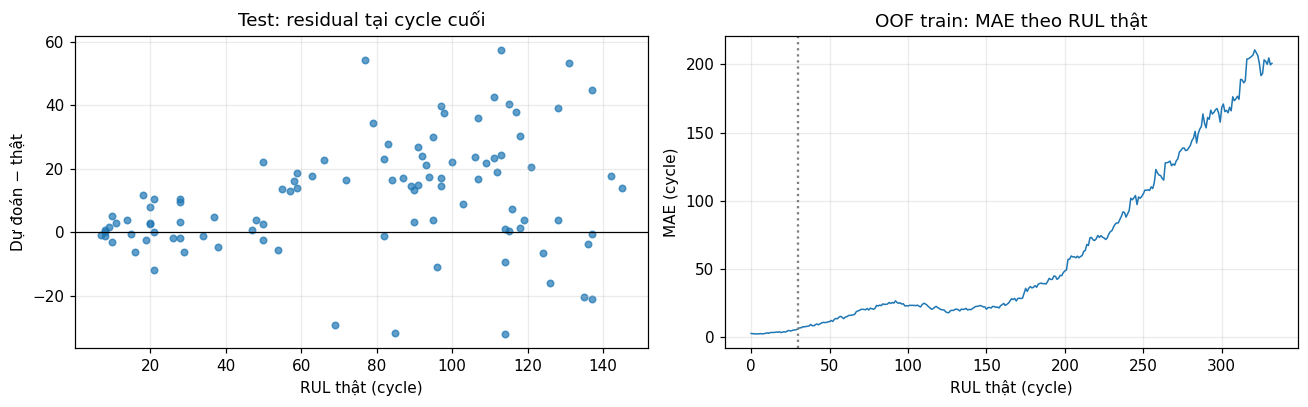

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(test_view["y_true"], test_view["residual"], s=18, alpha=0.7)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="RUL thật (cycle)", ylabel="Dự đoán − thật", title="Test: residual tại cycle cuối")
curve = oof_sel.groupby("y_true")["absolute_error"].mean()
axes[1].plot(curve.index, curve.values, linewidth=1)
axes[1].axvline(30, color="gray", linestyle=":")
axes[1].set(xlabel="RUL thật (cycle)", ylabel="MAE (cycle)", title="OOF train: MAE theo RUL thật")
plt.tight_layout()
fig.savefig(OUTPUT / "figures/residuals_by_life_stage.png", dpi=150)
plt.show()

In [12]:
oof_sel.groupby("rul_range", observed=True).agg(
    rows=("engine_id", "size"), mae=("absolute_error", "mean"), mean_residual=("residual", "mean")
)

,rows,mae,mean_residual
rul_range,,,
"(-1, 30]",3100,3.667627,1.474091
"(30, 60]",3000,10.679280,5.593871
"(60, 90]",3000,20.853957,14.515578
"(90, 120]",2931,23.336764,13.753506
"(120, 150]",2460,20.556662,-0.959510
"(150, 400]",3240,49.354450,-44.578146


Trên OOF train, MAE là 3.67 cycle ở vùng RUL không quá 30, tăng lên khoảng 20–23 cycle ở vùng 60–150
và đạt 49.35 cycle khi RUL trên 150. Nhóm cuối có residual trung bình −44.6: mô hình dự đoán RUL thấp hơn thực tế.

Ở đầu vòng đời, sensor chưa thể hiện suy giảm rõ. Hai động cơ còn 160 và 300 cycle có thể có tín hiệu
gần giống nhau, khiến mô hình khó phân biệt và dự đoán về mức trung bình.
Sai số ở giai đoạn này ít ảnh hưởng tới bảo trì vì chưa cần quyết định ngay.
Notebook 05 thử giới hạn trên của RUL khi huấn luyện để xử lý trường hợp này.

## 5. Từ quỹ đạo dự đoán đến thời điểm cảnh báo

Với mỗi động cơ train, lấy cycle đầu tiên có RUL dự đoán OOF ≤ 30.
So sánh thời điểm này với cycle mà RUL thật chạm 30. Chênh lệch dương nghĩa là báo trễ hơn mục tiêu.

Các dự đoán OOF đã dùng để chọn mô hình, nên phần cảnh báo là đánh giá nội bộ và có thể hơi lạc quan.
Ngưỡng 30 dùng để minh họa, chưa được hiệu chỉnh theo chi phí bảo trì.

In [13]:
from cmapss.modeling.early_warning import build_warning_events

events, warning_summary = build_warning_events(oof, model_name=selected, rul_threshold=30)
events.query("engine_id == 1")[
    ["engine_id", "actual_threshold_cycle", "first_warning_cycle",
     "threshold_delay_cycles", "lead_time_to_failure_cycles"]
]

,engine_id,actual_threshold_cycle,first_warning_cycle,threshold_delay_cycles,lead_time_to_failure_cycles
0,1,162,162,0,30.0


Hình dưới đặt quỹ đạo dự đoán của engine 1 cạnh mốc RUL = 30.
Cần phân biệt cảnh báo trước ngưỡng với báo nhầm: train ghi đủ đến khi hỏng, nên không có nhóm
động cơ không đi vào vùng RUL thấp để ước lượng tỷ lệ báo nhầm theo định nghĩa này.

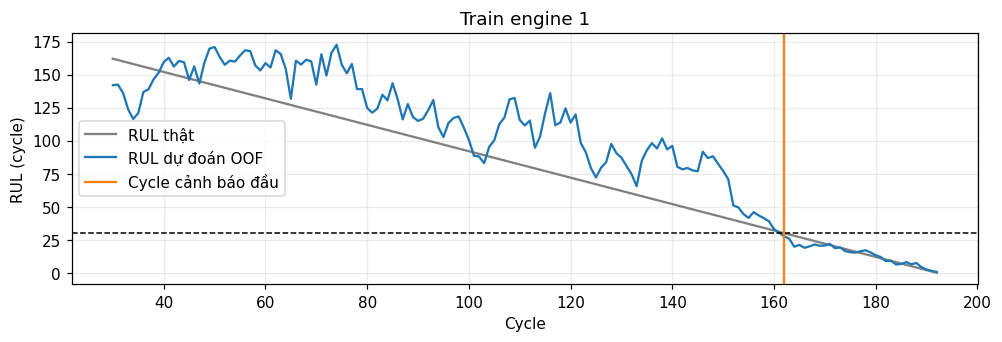

In [14]:
curve = oof_sel.query("engine_id == 1")
event = events.query("engine_id == 1").iloc[0]
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(curve.cycle, curve.y_true, label="RUL thật", color="0.5")
ax.plot(curve.cycle, curve.y_pred, label="RUL dự đoán OOF")
ax.axhline(30, color="black", linestyle="--", linewidth=1)
ax.axvline(event.first_warning_cycle, color="tab:orange", label="Cycle cảnh báo đầu")
ax.set(title="Train engine 1", xlabel="Cycle", ylabel="RUL (cycle)")
ax.legend()
fig.savefig(OUTPUT / "figures/engine1_warning.png", dpi=150)
plt.show()

In [15]:
pd.Series(warning_summary["timing_counts"], name="engines")

before_threshold    44
at_threshold         7
after_threshold     49
at_failure           0
no_warning           0
Name: engines, dtype: int64

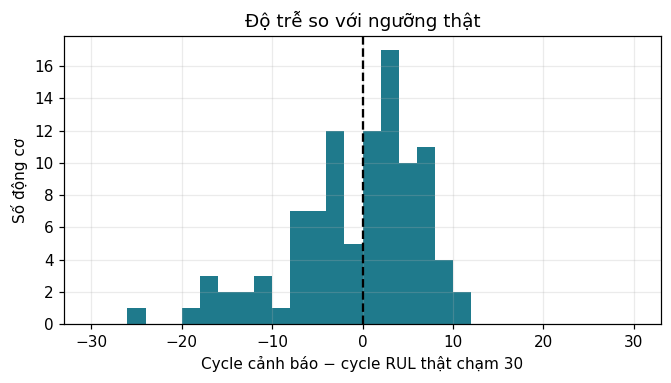

,threshold_delay_cycles,lead_time_to_failure_cycles
count,100.000000,100.000000
mean,-1.220000,31.220000
std,7.134466,7.134466
min,-25.000000,19.000000
25%,-5.000000,26.000000
50%,0.000000,30.000000
75%,4.000000,35.000000
max,11.000000,55.000000


In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(events["threshold_delay_cycles"], bins=range(-30, 31, 2), color="#1f7a8c")
ax.axvline(0, color="black", linestyle="--")
ax.set(xlabel="Cycle cảnh báo − cycle RUL thật chạm 30", ylabel="Số động cơ", title="Độ trễ so với ngưỡng thật")
plt.show()
events[["threshold_delay_cycles", "lead_time_to_failure_cycles"]].describe()

Cả 100 động cơ đều được cảnh báo trước khi hỏng. Có 44 động cơ được báo trước khi RUL thật chạm ngưỡng,
7 động cơ đúng ngưỡng và 49 động cơ trễ hơn. Độ trễ trung vị là 0 cycle, phần lớn từ −5 đến +4 cycle.

Thời gian từ cảnh báo đến hỏng trung bình 31.2 cycle, ngắn nhất 19 cycle.
Trên tập dữ liệu này, quy tắc để lại ít nhất 19 cycle để xử lý, nhưng gần một nửa số động cơ được báo
trễ hơn mục tiêu 30 cycle. Ngưỡng 30 hiện dùng để minh họa, chưa được xác định theo chi phí bảo trì thực tế.

In [17]:
assert len(evaluation) == evaluation.engine_id.nunique() == 100
assert len(oof_sel) == 17731 and len(events) == 100
print(f"Kết quả lần chạy: {OUTPUT.relative_to(ROOT)}")

Kết quả lần chạy: outputs\notebook03\run-m8g4wx9z


HGB đạt MAE thấp nhất trong ba phương án trên FD001, nhưng sai số phụ thuộc giai đoạn vòng đời.
Quy tắc RUL ≤ 30 còn để lại thời gian xử lý trước khi hỏng trên train; 49/100 động cơ vẫn được báo
trễ hơn mục tiêu 30 cycle trong kết quả baseline.

Notebook 04 chuyển sang dự báo Health Index, một bài toán khác với dự đoán RUL.
Notebook 06 dùng RUL dự đoán và dấu hiệu bất thường để lập lịch bảo trì.